# Deteção de sopros cardíacos (CirCor DigiScope)

Machine Learning II (CC3043), FCUP, 2026/2027. Para cada paciente prevemos, a partir das gravações de auscultação, se
tem um sopro (Present), se não tem (Absent) ou se não dá para saber (Unknown). Usamos dois modelos: uma CNN 1D sobre o
sinal dividido em bandas e uma BiGRU multitarefa sobre log-mel.

O notebook está dividido em 8 secções: regras do problema, dados, do áudio às entradas das redes, modelos, treino e
validação, avaliação, consequências práticas e próximos passos. Corremos tudo no CPU, porque o tensorflow-metal dá
resultados errados em Apple Silicon. Com `RETRAIN_* = False` o notebook usa os resultados guardados em `results/` e
corre em poucos minutos. O dataset é procurado em `../the-circor-digiscope-phonocardiogram-dataset-1.0.3/`, ou na
pasta indicada em `CIRCOR_DIR`.

In [1]:
import os, json
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
from scipy import signal
from scipy.io import wavfile
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedGroupKFold
import tensorflow as tf
import keras
from keras import layers
from src.training import run_cv, fold_data

tf.config.set_visible_devices([], "GPU")
SEED = 42
keras.utils.set_random_seed(SEED)

DATA_DIR = Path(os.environ.get("CIRCOR_DIR", "../the-circor-digiscope-phonocardiogram-dataset-1.0.3"))
REC_DIR = DATA_DIR / "training_data"
RESULTS, CACHE, FIGURES = Path("results"), Path("cache"), Path("results/figures")
SPLITS_CSV = Path("splits/splits.csv")
FIGURES.mkdir(parents=True, exist_ok=True)

CLASSES = ["Present", "Unknown", "Absent"]
PROB_COLS = [f"p_{c}" for c in CLASSES]
WEIGHTS = np.array([5.0, 3.0, 1.0])
SR_RAW, SR = 4000, 2000
BANDS = [(25, 45), (45, 80), (80, 200), (200, 400), (400, 800)]
WIN, RNN_WIN = 4 * SR, 250
MEL_HOP, MEL_WIN, N_MELS = 40, 100, 32
CLIP = 20.0

RETRAIN_CNN = False
RETRAIN_RNN = False

## 1. Regras do problema

Temos de dar uma previsão por paciente. Cada paciente tem várias gravações, uma por local de auscultação, mas o rótulo
é do paciente, e o sopro pode ouvir-se só em alguns locais (o campo Murmur locations diz quais). Os dados escondidos
podem não trazer os .tsv de segmentação, por isso só o áudio pode ser entrada dos modelos.

Falhar um sopro custa mais do que um falso alarme. A métrica do Challenge, a weighted accuracy (WA), conta cada Present
5 vezes, cada Unknown 3 vezes e cada Absent uma vez:

$$WA = \frac{5\,m_{PP} + 3\,m_{UU} + m_{AA}}{5\,n_P + 3\,n_U + n_A}$$

Daqui saem as duas regras com que passamos das probabilidades das gravações para uma classe por paciente. A primeira:
basta o sopro ouvir-se num local, por isso P(Present) do paciente é o máximo sobre as gravações (as outras duas são
médias, e no fim renormalizamos). A segunda: o denominador da WA não depende das previsões, logo o ganho esperado de
prever $c$ é $w_c\,p_c$, e escolhemos $\arg\max_c w_c p_c$ (a regra de Bayes para esta métrica) em vez do argmax normal.

Por fim, o protocolo: dividimos por paciente, guardamos 20% para teste sem lhe tocar até ao fim, e tomamos todas as
decisões com cross-validation de 5 folds nos restantes. Os asserts no fim da célula confirmam a métrica num exemplo
feito à mão e a diferença entre as duas regras de decisão.

In [2]:
def confusion_matrix_pua(y_true, y_pred):
    """Linhas = classe prevista, colunas = verdadeira, como na Tabela 1 do enunciado (o sklearn faz ao contrário)."""
    return confusion_matrix(y_true, y_pred, labels=CLASSES).T


def weighted_accuracy(y_true, y_pred):
    m = confusion_matrix_pua(y_true, y_pred)
    return float((WEIGHTS * np.diag(m)).sum() / (WEIGHTS * m.sum(axis=0)).sum())


def predict_patients(rec_probs, aggregation, decision):
    """Junta as gravações de cada paciente ("mean" ou "max_present") e escolhe a classe ("argmax" ou "bayes")."""
    g = rec_probs.groupby("patient_id")
    p = g[PROB_COLS].mean()
    if aggregation == "max_present":
        p["p_Present"] = g["p_Present"].max()
        p = p.div(p.sum(axis=1), axis=0)
    w = WEIGHTS if decision == "bayes" else 1.0
    p["pred"] = np.array(CLASSES)[np.argmax(p[PROB_COLS].to_numpy() * w, axis=1)]
    return p


y_true = ["Present", "Present", "Unknown", "Absent", "Absent", "Absent"]
y_pred = ["Present", "Absent", "Unknown", "Absent", "Present", "Absent"]
assert confusion_matrix_pua(["Present"], ["Absent"])[2, 0] == 1
assert np.isclose(weighted_accuracy(y_true, y_pred), (5 + 3 + 2) / (10 + 3 + 3))

example = pd.DataFrame({"patient_id": [1, 1, 2], "p_Present": [0.9, 0.1, 0.2],
                        "p_Unknown": [0.05, 0.1, 0.1], "p_Absent": [0.05, 0.8, 0.7]})
assert predict_patients(example, "mean", "argmax").loc[2, "pred"] == "Absent"
assert predict_patients(example, "mean", "bayes").loc[2, "pred"] == "Present"

## 2. Dados: limpeza e divisão

Há pacientes com um Additional ID, que aponta para outro paciente: são crianças gravadas nas duas campanhas (CC2014 e
CC2015), uma vez em cada. Se dividíssemos só pelo Patient ID, a mesma criança podia ficar no treino e no teste. Por
isso cada par fica com o mesmo group_id (o menor dos dois IDs), e é por esse grupo que dividimos.

In [3]:
patients = pd.read_csv(DATA_DIR / "training_data.csv").rename(columns={
    "Patient ID": "patient_id", "Recording locations:": "recording_locations", "Murmur": "murmur",
    "Murmur locations": "murmur_locations", "Campaign": "campaign", "Additional ID": "additional_id", "Age": "age"})
patients["additional_id"] = pd.to_numeric(patients["additional_id"], errors="coerce").astype("Int64")
patients["group_id"] = patients[["patient_id", "additional_id"]].min(axis=1).astype(int)

linked = patients.dropna(subset=["additional_id"])
pairs = set(zip(linked["patient_id"], linked["additional_id"].astype(int)))
assert pairs == {(b, a) for a, b in pairs}
print(f"{len(patients)} pacientes, {len(linked)} com Additional ID, {patients['group_id'].nunique()} crianças diferentes")

y = patients["murmur"]
display(pd.DataFrame({"pacientes": y.value_counts()[CLASSES],
                      "WA de prever sempre esta classe": [weighted_accuracy(y, [c] * len(y)) for c in CLASSES]}).round(3))
pd.crosstab(patients["campaign"], y, normalize="index")[CLASSES].round(3)

942 pacientes, 140 com Additional ID, 872 crianças diferentes


,pacientes,WA de prever sempre esta classe
murmur,,
Present,179,0.499
Unknown,68,0.114
Absent,695,0.387


murmur,Present,Unknown,Absent
campaign,,,
CC2014,0.164,0.052,0.784
CC2015,0.208,0.086,0.706


Prever sempre Absent dá a melhor accuracy, mas em WA quem ganha é prever sempre Present (0.499), e é essa a nossa
referência. As duas campanhas têm proporções de classes diferentes, por isso estratificamos por sopro x campanha.
Usamos duas vezes o StratifiedGroupKFold: o primeiro dos 5 folds dá o conjunto de teste e o resto é dividido em 5
folds de CV. A divisão fica guardada em splits/splits.csv, e o notebook confirma que volta a dar o mesmo.

In [4]:
def make_splits(patients, seed=SEED):
    strata = (patients["murmur"] + "_" + patients["campaign"]).to_numpy()
    groups = patients["group_id"].to_numpy()
    dev_idx, test_idx = next(StratifiedGroupKFold(5, shuffle=True, random_state=seed)
                             .split(np.zeros(len(patients)), strata, groups))
    out = patients[["patient_id", "group_id", "murmur", "campaign"]].copy()
    out["split"] = "dev"
    out.loc[out.index[test_idx], "split"] = "test"
    out["fold"] = -1
    inner = StratifiedGroupKFold(5, shuffle=True, random_state=seed)
    for k, (_, val_idx) in enumerate(inner.split(np.zeros(len(dev_idx)), strata[dev_idx], groups[dev_idx])):
        out.loc[out.index[dev_idx[val_idx]], "fold"] = k
    return out


splits = make_splits(patients)
assert (splits.groupby("group_id")[["split", "fold"]].nunique() == 1).all().all()
if SPLITS_CSV.exists():
    assert splits.equals(pd.read_csv(SPLITS_CSV))
else:
    SPLITS_CSV.parent.mkdir(exist_ok=True)
    splits.to_csv(SPLITS_CSV, index=False)
labels = splits.set_index("patient_id")["murmur"]
key = splits["split"].where(splits["split"] == "test", "fold " + splits["fold"].astype(str))
pd.crosstab(key, splits["murmur"], normalize="index")[CLASSES].round(3)

murmur,Present,Unknown,Absent
split,,,
fold 0,0.192,0.073,0.735
fold 1,0.185,0.073,0.742
fold 2,0.192,0.073,0.735
fold 3,0.187,0.073,0.740
fold 4,0.193,0.067,0.740
test,0.190,0.074,0.735


Os folds e o teste ficam com proporções quase iguais. Falta o rótulo de cada gravação. Num paciente Present o sopro
pode não se ouvir em todos os locais, e se cada gravação herdasse o rótulo do paciente estaríamos a ensinar à rede que
gravações sem sopro são Present. Por isso essas gravações ficam Absent. A partir daqui só usamos o conjunto de
desenvolvimento, incluindo na exploração do áudio.

In [5]:
def recording_label(murmur, murmur_locations, location):
    if murmur != "Present":
        return murmur
    return "Present" if location in str(murmur_locations).split("+") else "Absent"


assert recording_label("Present", "AV+TV", "TV") == "Present" and recording_label("Present", "AV+TV", "MV") == "Absent"

rows = []
for p in patients.itertuples(index=False):
    lines = (REC_DIR / f"{p.patient_id}.txt").read_text().splitlines()
    for line in lines[1:1 + int(lines[0].split()[1])]:
        location, hea, wav, tsv = line.split()
        rows.append(dict(patient_id=p.patient_id, recording=wav[:-4], location=location, wav=str(REC_DIR / wav),
                         tsv=str(REC_DIR / tsv), duration=int((REC_DIR / hea).read_text().split()[3]) / SR_RAW,
                         patient_label=p.murmur, rec_label=recording_label(p.murmur, p.murmur_locations, location)))
recs = pd.DataFrame(rows)
dev_ids = set(splits.loc[splits["split"] == "dev", "patient_id"])
dev_recs = recs[recs["patient_id"].isin(dev_ids)].reset_index(drop=True)

present = patients[patients["patient_id"].isin(dev_ids) & (patients["murmur"] == "Present")]
partial = present["murmur_locations"].str.split("+").apply(set) != present["recording_locations"].str.split("+").apply(set)
print(f"{len(recs)} gravações; no desenvolvimento {len(dev_ids)} pacientes e {len(dev_recs)} gravações, "
      f"a mais curta com {dev_recs['duration'].min():.1f} s")
print(f"pacientes Present em que o sopro não se ouve em todos os locais: {partial.sum()} de {len(present)}")
for col in ["Systolic murmur timing", "Systolic murmur pitch", "Systolic murmur grading"]:
    print(col, present[col].value_counts().to_dict())

3163 gravações; no desenvolvimento 753 pacientes e 2549 gravações, a mais curta com 5.2 s
pacientes Present em que o sopro não se ouve em todos os locais: 54 de 143
Systolic murmur timing {'Holosystolic': 84, 'Early-systolic': 44, 'Mid-systolic': 14}
Systolic murmur pitch {'Low': 68, 'Medium': 39, 'High': 35}
Systolic murmur grading {'I/VI': 82, 'III/VI': 39, 'II/VI': 21}


Todas as gravações têm mais de 5 s, por isso dá sempre para tirar janelas de 4 s sem padding. Em 54 de 143 pacientes
Present o sopro não se ouve em todos os locais, o que confirma que os rótulos por local fazem falta. Quase todos os
sopros são sistólicos, muitos têm tom médio ou alto, e o grau mais comum é o I/VI, o mais fraco.

## 3. Do áudio às entradas das redes

Os .tsv dividem cada gravação em S1, sístole, S2 e diástole (estado 0 = não anotado). Começamos por ver quanto de cada
gravação ficou por anotar e quanto dura um ciclo cardíaco.

In [6]:
def read_tsv(path):
    return np.loadtxt(path, ndmin=2)


def cycle_length(seg):
    """Mediana dos intervalos entre S1 seguidos, sem os que saem de 0.2-2 s."""
    d = np.diff(seg[seg[:, 2] == 1, 0])
    return np.median(d[(d > 0.2) & (d < 2.0)]) if len(d) else np.nan


segs = [read_tsv(t) for t in dev_recs["tsv"]]
dev_recs["unannotated"] = [1.0 - sum(e - s for s, e, st in seg if st != 0) / d
                           for seg, d in zip(segs, dev_recs["duration"])]
dev_recs["cycle_s"] = [cycle_length(seg) for seg in segs]
print("fração média sem anotação:", dev_recs.groupby("patient_label")["unannotated"].mean().round(2).to_dict())
print(f"ciclo cardíaco: mediana {dev_recs['cycle_s'].median():.2f} s, percentil 95 {dev_recs['cycle_s'].quantile(0.95):.2f} s")

fração média sem anotação: {'Absent': 0.45, 'Present': 0.41, 'Unknown': 0.69}
ciclo cardíaco: mediana 0.58 s, percentil 95 0.81 s


As gravações Unknown têm muito mais tempo sem anotação do que as outras, ou seja, o Unknown é sobretudo uma questão de
qualidade do sinal. Por isso a RNN vai ter uma saída extra que aprende a prever o estado de cada frame, incluindo o 0,
com os .tsv só como alvo de treino. O ciclo dura quase sempre menos de 1 s, por isso uma janela de 4 s apanha vários
batimentos. Em baixo, uma gravação com um sopro forte e outra de um paciente Absent:

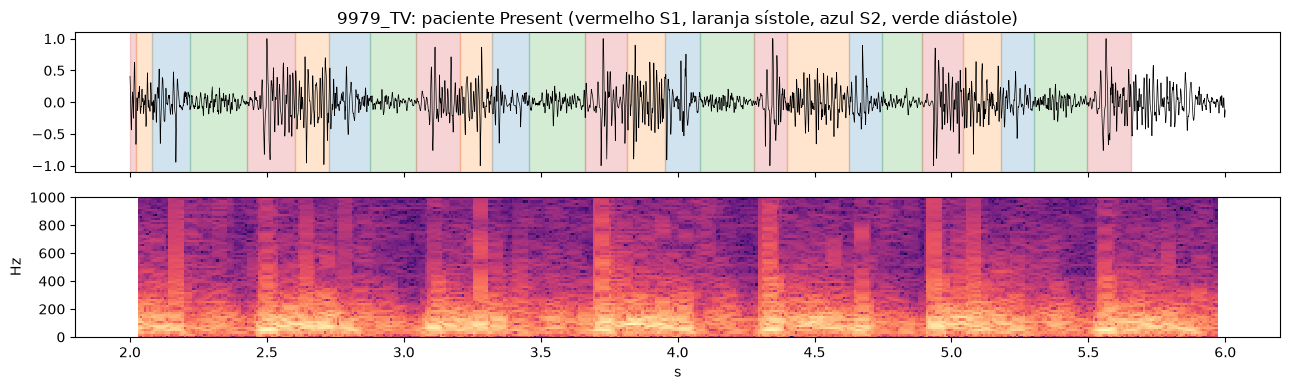

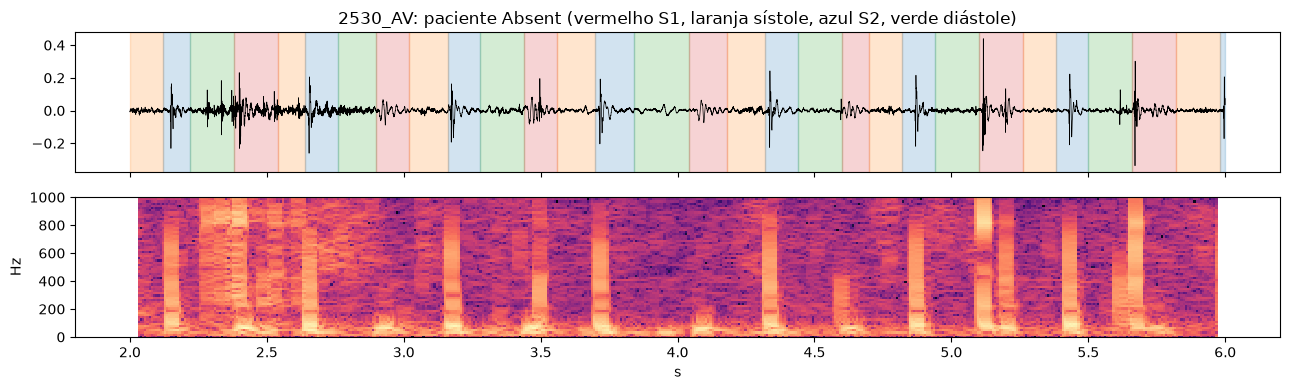

In [7]:
def load_wav(path):
    sr, x = wavfile.read(path)
    assert sr == SR_RAW
    return x.astype(np.float32) / 32768.0


def show_recording(name, t0=2.0, t1=6.0):
    """Um bocado da gravação com as fases do .tsv pintadas por cima e o espectrograma por baixo."""
    r = dev_recs.set_index("recording").loc[name]
    x = load_wav(r["wav"])
    t = np.arange(len(x)) / SR_RAW
    sel = (t >= t0) & (t < t1)
    fig, axes = plt.subplots(2, 1, figsize=(13, 4), sharex=True)
    axes[0].plot(t[sel], x[sel], lw=0.5, color="black")
    for start, end, s in read_tsv(r["tsv"]):
        if s > 0 and end > t0 and start < t1:
            axes[0].axvspan(max(start, t0), min(end, t1), color=["tab:red", "tab:orange", "tab:blue", "tab:green"][int(s) - 1], alpha=0.2)
    axes[0].set_title(f"{name}: paciente {r['patient_label']} (vermelho S1, laranja sístole, azul S2, verde diástole)")
    f, tt, S = signal.spectrogram(x[sel], fs=SR_RAW, nperseg=256, noverlap=224)
    axes[1].pcolormesh(tt + t0, f, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma")
    axes[1].set_ylim(0, 1000); axes[1].set_ylabel("Hz"); axes[1].set_xlabel("s")
    plt.tight_layout(); plt.show()


show_recording("9979_TV")
show_recording("2530_AV")

Com sopro, a sístole fica cheia de energia em banda larga. Sem sopro, entre os sons cardíacos há silêncio. Mas muitos
sopros são fracos e quase não se veem. Para perceber em que frequências está a diferença comparamos o espectro médio
das gravações Present e Absent, na gravação inteira e só na sístole:

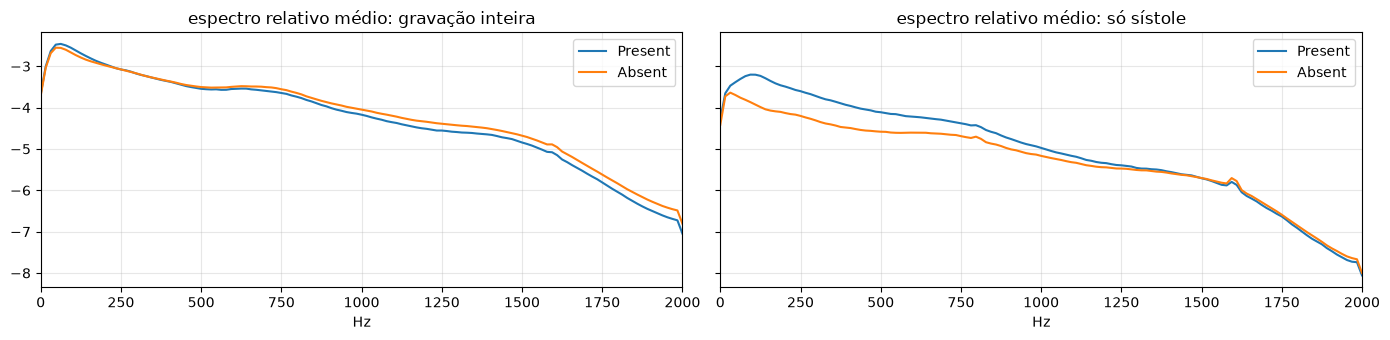

Present menos Absent em log10 da potência (+0.30 = o dobro):


,25-100 Hz,100-200 Hz,200-400 Hz,400-800 Hz,800-2000 Hz
gravação inteira,0.09,0.08,0.00,-0.06,-0.17
só sístole,0.43,0.71,0.59,0.40,0.05


In [8]:
def mean_spectrum(label, systole_only):
    """Espectro médio (Welch) das gravações com este rótulo, relativo à potência total de cada gravação."""
    out = []
    for wav, tsv in dev_recs.loc[dev_recs["rec_label"] == label, ["wav", "tsv"]].itertuples(index=False):
        x = load_wav(wav)
        if systole_only:
            parts = [x[int(s * SR_RAW):int(e * SR_RAW)] for s, e, st in read_tsv(tsv) if st == 2]
            parts = [q - q.mean() for q in parts if len(q) > 64]
            if not parts:
                continue
            p = np.mean([signal.welch(q, fs=SR_RAW, nperseg=min(256, len(q)), nfft=256)[1] for q in parts], axis=0)
        else:
            p = signal.welch(x, fs=SR_RAW, nperseg=256, nfft=256)[1]
        out.append(np.log10(p / np.mean(x ** 2) + 1e-12))
    return np.mean(out, axis=0)


freqs = np.fft.rfftfreq(256, 1 / SR_RAW)
spectra = {(lab_, sys_): mean_spectrum(lab_, sys_) for lab_ in ["Present", "Absent"] for sys_ in [False, True]}
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), sharey=True)
for ax, sys_, title in [(axes[0], False, "gravação inteira"), (axes[1], True, "só sístole")]:
    for lab_ in ["Present", "Absent"]:
        ax.plot(freqs, spectra[lab_, sys_], label=lab_)
    ax.set(xlim=(0, 2000), xlabel="Hz", title=f"espectro relativo médio: {title}"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(FIGURES / "eda_spectra.png", dpi=120); plt.show()

diff = {f"{lo}-{hi} Hz": [np.mean(spectra["Present", s][(freqs >= lo) & (freqs < hi)] - spectra["Absent", s][(freqs >= lo) & (freqs < hi)])
                          for s in [False, True]] for lo, hi in [(25, 100), (100, 200), (200, 400), (400, 800), (800, 2000)]}
print("Present menos Absent em log10 da potência (+0.30 = o dobro):")
pd.DataFrame(diff, index=["gravação inteira", "só sístole"]).round(2)

Na gravação inteira as duas classes quase não se distinguem, porque o S1 e o S2 dominam. Dentro da sístole, as
Present têm 2.5 a 5 vezes mais potência entre 25 e 800 Hz e praticamente a mesma acima disso. Daqui saem as entradas
dos dois modelos.

Na CNN passamos o sinal para 2 kHz e dividimo-lo em 5 bandas entre 25 e 800 Hz (as quatro primeiras são as de Potes et
al., que ganharam o Challenge de 2016), com filtros de fase zero para o S1 e o S2 ficarem alinhados. Cada banda é
normalizada com a mediana e o MAD, porque os picos de fricção estragavam a média, e cortamos em ±20. No treino tiramos
crops aleatórios de 4 s; na inferência usamos janelas de 4 s com 50% de sobreposição.

Na RNN usamos um log-mel com 32 bandas entre 25 e 800 Hz (janelas de 50 ms de 20 em 20 ms), normalizado por banda, e o
estado do .tsv no centro de cada frame como alvo auxiliar. No treino usamos crops de 5 s (250 frames). As entradas das
duas redes ficam guardadas em cache/, para não as recalcular.

In [9]:
SOS = [signal.butter(4, band, btype="bandpass", fs=SR, output="sos") for band in BANDS]


def downsample(x):
    return signal.resample_poly(x, 1, SR_RAW // SR).astype(np.float32)


def preprocess_cnn(wav):
    x = downsample(load_wav(wav))
    x = np.stack([signal.sosfiltfilt(sos, x) for sos in SOS], axis=-1).astype(np.float32)
    med = np.median(x, axis=0)
    mad = np.median(np.abs(x - med), axis=0) * 1.4826
    return np.clip((x - med) / (mad + 1e-8), -CLIP, CLIP).astype(np.float32)


def logmel(x):
    mel = librosa.feature.melspectrogram(y=x, sr=SR, n_fft=256, win_length=MEL_WIN, hop_length=MEL_HOP,
                                         n_mels=N_MELS, fmin=25, fmax=800)
    z = np.log(mel + 1e-8).T
    return ((z - z.mean(axis=0)) / (z.std(axis=0) + 1e-6)).astype(np.float32)


def frame_labels(seg, n_frames):
    """Estado do .tsv no centro de cada frame (o librosa centra a frame i em i * hop). Fora das anotações fica 0."""
    t = np.arange(n_frames) * (MEL_HOP / SR)
    idx = np.searchsorted(seg[:, 0], t, side="right") - 1
    inside = (idx >= 0) & (t < seg[np.clip(idx, 0, None), 1])
    return np.where(inside, seg[np.clip(idx, 0, None), 2], 0).astype(np.int32)


def preprocess_rnn(wav, tsv):
    x = logmel(downsample(load_wav(wav)))
    return x, frame_labels(read_tsv(tsv), len(x))


def load_inputs(kind, recordings):
    """Entradas da CNN ou da RNN para cada gravação, guardadas em cache/<kind>/ na primeira vez."""
    out, folder = {}, CACHE / kind
    folder.mkdir(parents=True, exist_ok=True)
    for r in recordings.itertuples():
        f = folder / f"{r.recording}.npz"
        if not f.exists():
            if kind == "cnn":
                np.savez(f, x=preprocess_cnn(r.wav).astype(np.float16))
            else:
                x, s = preprocess_rnn(r.wav, r.tsv)
                np.savez(f, x=x.astype(np.float16), s=s.astype(np.int8))
        d = np.load(f)
        out[r.recording] = d["x"] if kind == "cnn" else (d["x"], d["s"])
    return out

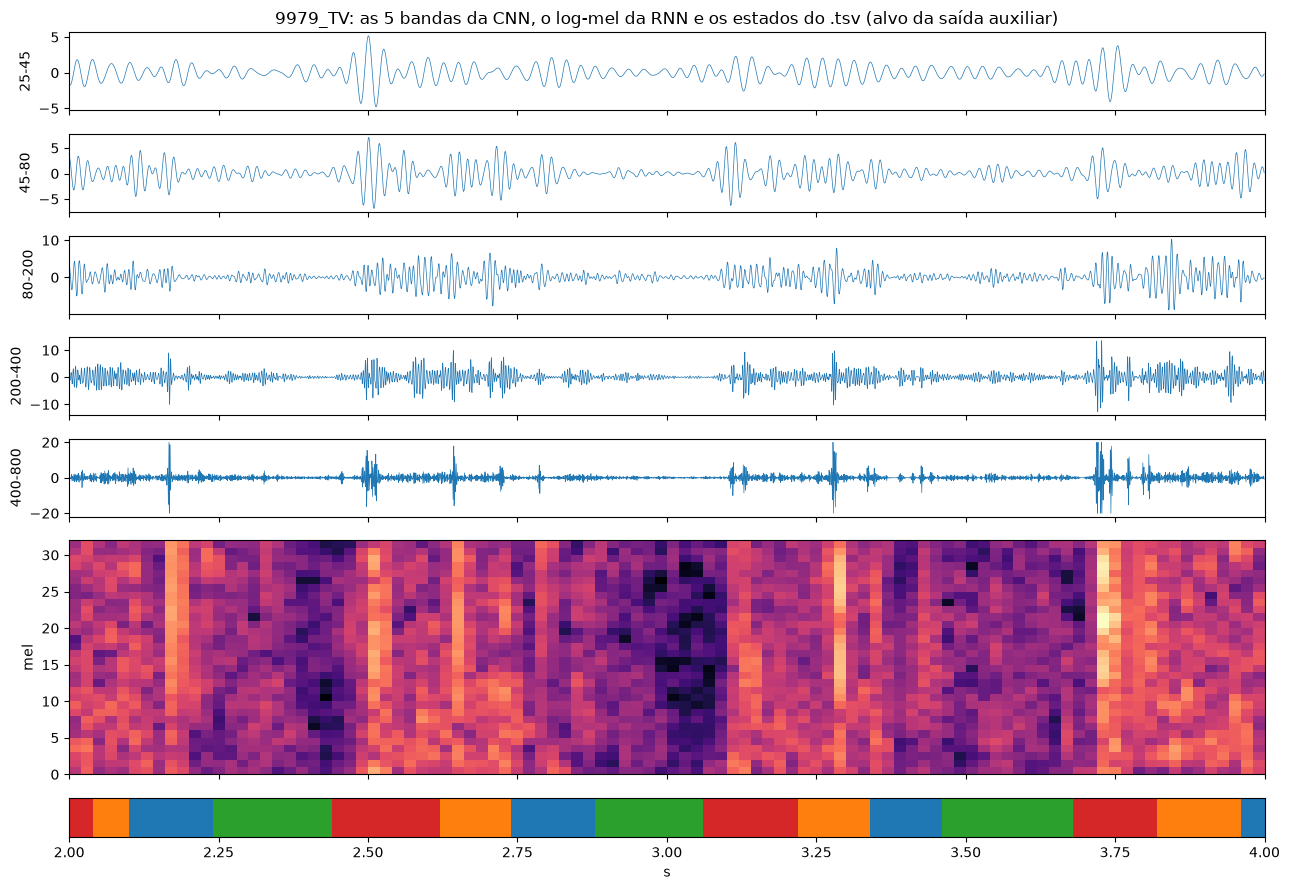

fração de amostras cortadas em ±20, em 300 gravações ao acaso: 0.0072


In [10]:
r = dev_recs.set_index("recording").loc["9979_TV"]
z, (mel, states) = preprocess_cnn(r["wav"]), preprocess_rnn(r["wav"], r["tsv"])
t = np.arange(len(z)) / SR
fig, axes = plt.subplots(len(BANDS) + 2, 1, figsize=(13, 9), sharex=True,
                         gridspec_kw={"height_ratios": [1] * len(BANDS) + [3, 0.5]})
for ax, (lo, hi), band in zip(axes, BANDS, z[(t >= 2) & (t < 4)].T):
    ax.plot(t[(t >= 2) & (t < 4)], band, lw=0.5); ax.set_ylabel(f"{lo}-{hi}")
tf_ = np.arange(len(mel)) * MEL_HOP / SR
sel = (tf_ >= 2) & (tf_ < 4)
axes[-2].imshow(mel[sel].T, origin="lower", aspect="auto", cmap="magma", extent=[2, 4, 0, N_MELS]); axes[-2].set_ylabel("mel")
axes[-1].imshow(states[sel][None], aspect="auto", vmin=0, vmax=4, extent=[2, 4, 0, 1],
                cmap=plt.matplotlib.colors.ListedColormap(["lightgray", "tab:red", "tab:orange", "tab:blue", "tab:green"]))
axes[-1].set_yticks([]); axes[-1].set_xlabel("s")
axes[0].set_title("9979_TV: as 5 bandas da CNN, o log-mel da RNN e os estados do .tsv (alvo da saída auxiliar)")
plt.tight_layout(); plt.show()

clipped = np.mean([(np.abs(preprocess_cnn(w)) >= CLIP).mean() for w in dev_recs.sample(300, random_state=SEED)["wav"]])
print(f"fração de amostras cortadas em ±20, em 300 gravações ao acaso: {clipped:.4f}")

## 4. Modelos

A CNN 1D recebe 4 s em 5 bandas (8000 x 5) e tem cinco blocos de Conv1D (kernel 9), BatchNorm, ReLU e MaxPool, com 16,
32, 64, 128 e 128 filtros e pooling de 4, 4, 4, 2 e 2, escolhidos para o receptive field da última conv cobrir mais ou
menos um ciclo. No fim tem global average pooling (o sopro repete-se em todos os batimentos), dropout de 0.5 e softmax.

A RNN tem duas camadas BiGRU de 64 unidades (GRU em vez de LSTM porque tem menos parâmetros, e só temos ~2000
gravações de treino por fold) e duas saídas. A "seg" prevê o estado de cada frame. A "murmur" dá a classe da gravação a
partir de uma média pesada das frames (attention pooling), porque o sopro só aparece em parte delas. A loss é
$CE_{murmur} + 0.5\,CE_{seg}$, e na inferência só usamos a "murmur".

Os dois modelos são treinados com Adam (learning rate 1e-3), batches de 32 e early stopping na WA por paciente do fold
de validação (paciência de 10 épocas, no máximo 60). Não usamos a val_loss porque é calculada por crop e não reflete a
decisão por paciente. Na CNN usamos ainda augmentation com ganho e polaridade aleatórios (não invertemos no tempo
porque isso trocava o S1 com o S2). Para o desequilíbrio das classes comparámos duas configurações da CNN:

| | loss | agregação | decisão |
|---|---|---|---|
| E1 | cross-entropy com class weights | média | argmax |
| E2 | cross-entropy sem pesos | máximo para Present | regra de Bayes |

A E2 segue as regras da secção 1 e não põe pesos na loss, para não contar os custos duas vezes. O código genérico do
treino (dataset de crops, inferência por janelas, callback de early stopping e ciclo de CV) está em src/training.py.

In [11]:
CNN_BLOCKS = ((16, 4), (32, 4), (64, 4), (128, 2), (128, 2))


def build_cnn1d():
    inp = keras.Input(shape=(WIN, len(BANDS)))
    x = inp
    for filters, pool in CNN_BLOCKS:
        x = layers.Conv1D(filters, 9, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling1D(pool)(x)
    x = layers.Dropout(0.5)(layers.GlobalAveragePooling1D()(x))
    return keras.Model(inp, layers.Dense(3, activation="softmax", name="murmur")(x))


def receptive_field():
    """Cada conv soma 8 passos e cada pooling (menos o último) soma pool - 1 e multiplica o tamanho do passo."""
    rf, jump = 1, 1
    for i, (_, pool) in enumerate(CNN_BLOCKS):
        rf += 8 * jump
        if i < len(CNN_BLOCKS) - 1:
            rf += (pool - 1) * jump
            jump *= pool
    return rf


def build_bigru_mt():
    inp = keras.Input(shape=(None, N_MELS))
    x = inp
    for _ in range(2):
        x = layers.Bidirectional(layers.GRU(64, return_sequences=True, dropout=0.1))(x)
    seg = layers.Dense(5, activation="softmax", name="seg")(x)
    att = layers.Softmax(axis=1)(layers.Dense(1)(x))
    h = layers.Dropout(0.3)(layers.Flatten()(layers.Dot(axes=1)([att, x])))
    h = layers.Dense(32, activation="relu")(h)
    murmur = layers.Dense(3, activation="softmax", name="murmur")(h)
    return keras.Model(inp, {"murmur": murmur, "seg": seg})


print(f"CNN: {build_cnn1d().count_params()} parâmetros, receptive field de {receptive_field() / SR:.2f} s "
      f"(ciclo mediano: {dev_recs['cycle_s'].median():.2f} s)")
print(f"BiGRU: {build_bigru_mt().count_params()} parâmetros")

CNN: 246803 parâmetros, receptive field de 0.92 s (ciclo mediano: 0.58 s)
BiGRU: 117129 parâmetros


## 5. Treino e validação

Cada configuração da CNN é treinada nos 5 folds do desenvolvimento, e cada paciente é previsto pelo modelo do fold em
que ficou de fora (previsões out-of-fold). Com `RETRAIN_CNN = False` carregamos as previsões guardadas em results/,
porque treinar tudo outra vez demora uns 35 min no CPU. O conjunto de teste continua fechado: só o vamos usar uma vez,
no fim, com o ensemble dos modelos dos folds.

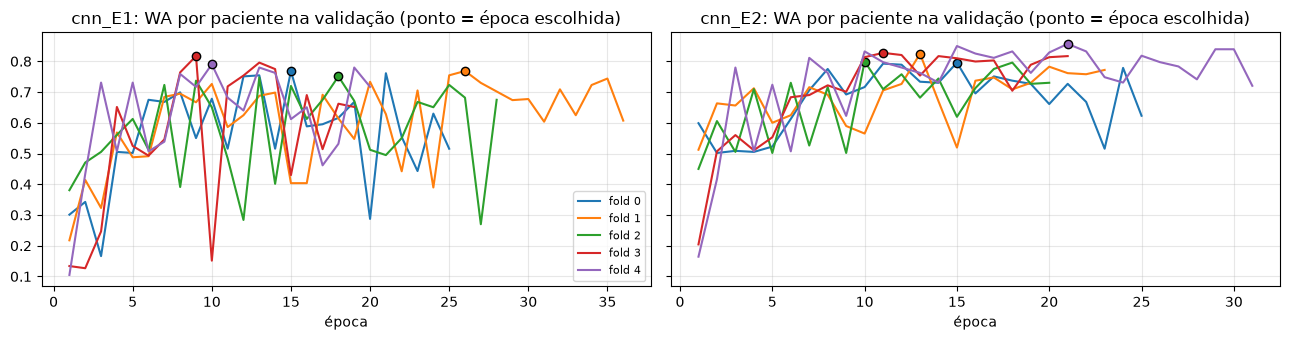

In [12]:
def wa_score(aggregation, decision):
    """O que o early stopping vigia: agrega as gravações por paciente, decide e calcula a WA."""
    def score(rec_probs):
        pp = predict_patients(rec_probs, aggregation, decision)
        return weighted_accuracy(labels.loc[pp.index], pp["pred"])
    return score


VARIANTS = {"cnn_E1": dict(class_weighted=True, aggregation="mean", decision="argmax"),
            "cnn_E2": dict(class_weighted=False, aggregation="max_present", decision="bayes")}
OOF, HIST = {}, {}
for name, v in VARIANTS.items():
    oof_path, hist_path = RESULTS / f"{name}_oof.csv", RESULTS / f"{name}_histories.json"
    if RETRAIN_CNN or not (oof_path.exists() and hist_path.exists()):
        oof, hist = run_cv(build_cnn1d, load_inputs("cnn", dev_recs), dev_recs, splits, name, WIN, CLASSES,
                           wa_score(v["aggregation"], v["decision"]), class_weighted=v["class_weighted"],
                           seed=SEED, models_dir=RESULTS / "models")
        oof.to_csv(oof_path, index=False)
        hist_path.write_text(json.dumps({k: {m: [float(x) for x in vals] for m, vals in h.items()} for k, h in hist.items()}))
    OOF[name] = pd.read_csv(oof_path)
    HIST[name] = {int(k): h for k, h in json.loads(hist_path.read_text()).items()}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for ax, name in zip(axes, VARIANTS):
    for k, h in HIST[name].items():
        wa = np.array(h["val_patient_wa"])
        ax.plot(np.arange(1, len(wa) + 1), wa, color=f"C{k}", label=f"fold {k}")
        ax.plot(wa.argmax() + 1, wa.max(), "o", color=f"C{k}", markeredgecolor="black")
    ax.set(title=f"{name}: WA por paciente na validação (ponto = época escolhida)", xlabel="época"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "cnn_learning_curves.png", dpi=120); plt.show()

As curvas da E1 são muito mais instáveis do que as da E2, com a WA a saltar de uma época para a outra. A RNN ainda só
tem um smoke run: 10 épocas no fold 0, com as mesmas regras da E2 e sem augmentation. Serve para confirmar que o
pipeline funciona e que a saída auxiliar aprende o ciclo cardíaco.

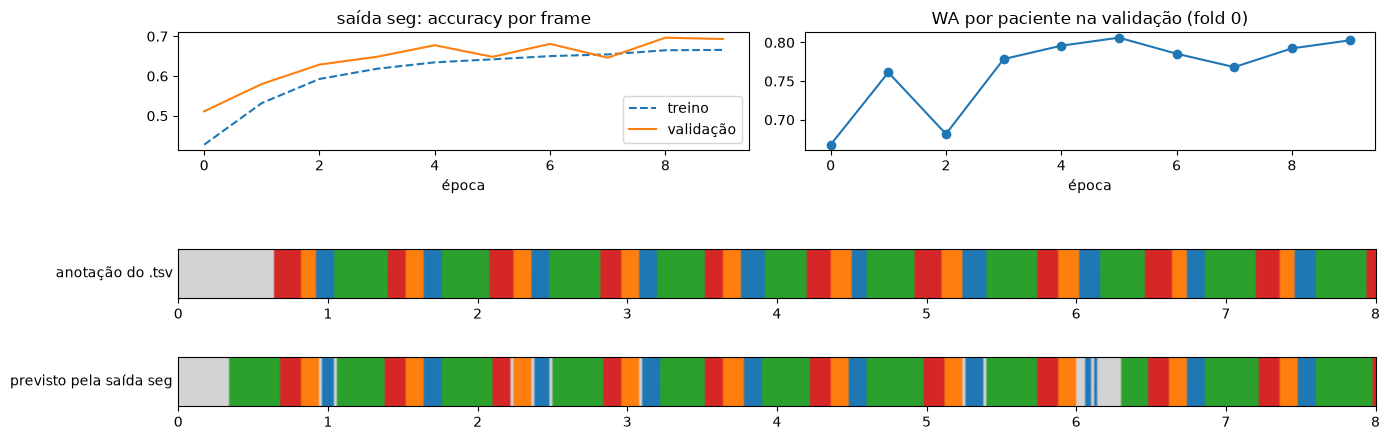

accuracy por frame a prever sempre o estado mais frequente: 0.473


In [13]:
rnn = load_inputs("rnn", dev_recs)
rnn_oof_path, rnn_hist_path = RESULTS / "rnn_smoke_oof.csv", RESULTS / "rnn_smoke_history.json"
rnn_model_path = RESULTS / "models" / "rnn_smoke_fold0.keras"
if RETRAIN_RNN or not (rnn_oof_path.exists() and rnn_hist_path.exists() and rnn_model_path.exists()):
    rnn_oof, hist = run_cv(build_bigru_mt, rnn, dev_recs, splits, "rnn_smoke", RNN_WIN, CLASSES,
                           wa_score("max_present", "bayes"), folds=[0], epochs=10, multitask=True,
                           loss_weights={"murmur": 1.0, "seg": 0.5}, seed=SEED, models_dir=RESULTS / "models")
    rnn_oof.to_csv(rnn_oof_path, index=False)
    rnn_hist_path.write_text(json.dumps({m: [float(x) for x in vals] for m, vals in hist[0].items()}))
rnn_oof, h = pd.read_csv(rnn_oof_path), json.loads(rnn_hist_path.read_text())

_, va = fold_data(dev_recs, splits, 0)
name = va.loc[va["rec_label"] == "Present", "recording"].iloc[0]
x, s = rnn[name]
pred_states = keras.models.load_model(rnn_model_path).predict(x[None].astype(np.float32), verbose=0)["seg"][0].argmax(-1)

fig = plt.figure(figsize=(14, 4.5))
ax1, ax2 = fig.add_subplot(2, 2, 1), fig.add_subplot(2, 2, 2)
ax1.plot(h["seg_accuracy"], "--", label="treino"); ax1.plot(h["val_seg_accuracy"], label="validação")
ax1.set(title="saída seg: accuracy por frame", xlabel="época"); ax1.legend()
ax2.plot(h["val_patient_wa"], "o-"); ax2.set(title="WA por paciente na validação (fold 0)", xlabel="época")
cmap = plt.matplotlib.colors.ListedColormap(["lightgray", "tab:red", "tab:orange", "tab:blue", "tab:green"])
for i, (st, title) in enumerate([(s, "anotação do .tsv"), (pred_states, "previsto pela saída seg")]):
    ax = fig.add_subplot(4, 1, 3 + i)
    ax.imshow(st[None, :400], aspect="auto", cmap=cmap, vmin=0, vmax=4, extent=[0, 400 * MEL_HOP / SR, 0, 1])
    ax.set_yticks([]); ax.set_ylabel(title, rotation=0, ha="right", va="center")
plt.tight_layout(); plt.savefig(FIGURES / "rnn_smoke_curves.png", dpi=120); plt.show()
all_states = np.concatenate([v[1] for v in rnn.values()])
print(f"accuracy por frame a prever sempre o estado mais frequente: {np.bincount(all_states).max() / len(all_states):.3f}")

## 6. Avaliação e métricas

Para cada configuração mostramos a WA de cada fold (média ± desvio padrão), a matriz de confusão com os folds todos
juntos (linhas = previsto) e, como métrica adicional, o recall de cada classe.

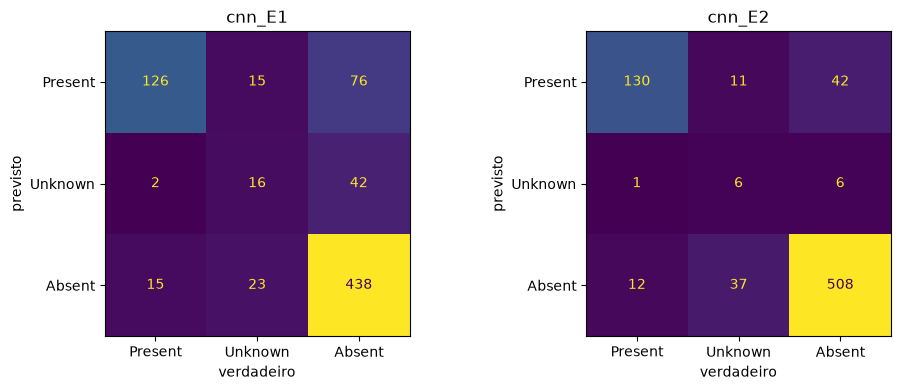

,fold 0,fold 1,fold 2,fold 3,fold 4,WA_mean,WA_std,recall_Present,recall_Unknown,recall_Absent
model,,,,,,,,,,
cnn_E1,0.768,0.768,0.751,0.817,0.790,0.779,0.025,0.881,0.296,0.788
cnn_E2,0.796,0.825,0.799,0.827,0.857,0.821,0.025,0.909,0.111,0.914


RNN, smoke run no fold 0: WA 0.806 (CNN E2 no mesmo fold: 0.796), Unknown reconhecidos: 0 de 11


In [14]:
def evaluate(oof, aggregation, decision):
    """WA de cada fold e previsões por paciente com os folds todos juntos."""
    per_fold = []
    for _, g in oof.groupby("fold"):
        pp = predict_patients(g, aggregation, decision)
        per_fold.append(weighted_accuracy(labels.loc[pp.index], pp["pred"]))
    return np.array(per_fold), predict_patients(oof, aggregation, decision)


rows, pooled = [], {}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, v) in zip(axes, VARIANTS.items()):
    per_fold, pp = evaluate(OOF[name], v["aggregation"], v["decision"])
    pooled[name] = confusion_matrix_pua(labels.loc[pp.index], pp["pred"])
    rows.append(dict(model=name, **{f"fold {k}": wa for k, wa in enumerate(per_fold)},
                     WA_mean=per_fold.mean(), WA_std=per_fold.std(ddof=1)))
    ConfusionMatrixDisplay(pooled[name], display_labels=CLASSES).plot(ax=ax, colorbar=False)
    ax.set(title=name, xlabel="verdadeiro", ylabel="previsto")
plt.tight_layout(); plt.savefig(FIGURES / "cnn_confusion_matrices.png", dpi=120); plt.show()

summary = pd.DataFrame(rows).set_index("model")
summary.to_csv(RESULTS / "cnn_cv_summary.csv")
recall = pd.DataFrame({name: np.diag(m) / m.sum(axis=0) for name, m in pooled.items()}, index=CLASSES).T
display(summary.join(recall.add_prefix("recall_")).round(3))

pp = predict_patients(rnn_oof, "max_present", "bayes")
m = confusion_matrix_pua(labels.loc[pp.index], pp["pred"])
print(f"RNN, smoke run no fold 0: WA {weighted_accuracy(labels.loc[pp.index], pp['pred']):.3f} "
      f"(CNN E2 no mesmo fold: {summary.loc['cnn_E2', 'fold 0']:.3f}), Unknown reconhecidos: {m[1, 1]} de {m[:, 1].sum()}")

Como guardámos as probabilidades de cada gravação, dá para testar todas as combinações de agregação e decisão sem voltar
a treinar, e assim separar o efeito da loss do efeito da decisão:

In [15]:
rows = []
for name in VARIANTS:
    for aggregation in ["mean", "max_present"]:
        for decision in ["argmax", "bayes"]:
            per_fold, pp = evaluate(OOF[name], aggregation, decision)
            m = confusion_matrix_pua(labels.loc[pp.index], pp["pred"])
            rec = np.diag(m) / m.sum(axis=0)
            rows.append(dict(training=name, aggregation=aggregation, decision=decision, WA_mean=per_fold.mean(),
                             WA_std=per_fold.std(ddof=1), recall_P=rec[0], recall_U=rec[1], recall_A=rec[2]))
posthoc = pd.DataFrame(rows)
posthoc.to_csv(RESULTS / "cnn_posthoc_rules.csv", index=False)
posthoc.round(3)

,training,aggregation,decision,WA_mean,WA_std,recall_P,recall_U,recall_A
0,cnn_E1,mean,argmax,0.779,0.025,0.881,0.296,0.788
1,cnn_E1,mean,bayes,0.569,0.059,0.993,0.241,0.121
2,cnn_E1,max_present,argmax,0.765,0.027,0.937,0.278,0.685
3,cnn_E1,max_present,bayes,0.543,0.040,0.993,0.222,0.058
4,cnn_E2,mean,argmax,0.667,0.035,0.559,0.000,0.998
5,cnn_E2,mean,bayes,0.776,0.041,0.783,0.111,0.959
6,cnn_E2,max_present,argmax,0.693,0.050,0.615,0.000,0.995
7,cnn_E2,max_present,bayes,0.821,0.025,0.909,0.111,0.914


A E2 ganha à E1 em todos os folds (0.821 ± 0.025 contra 0.779 ± 0.025; prever sempre Present dá 0.499), e a última
tabela mostra porquê. Com as mesmas probabilidades, a E2 com argmax fica em 0.693 e com a regra de Bayes sobe para
0.821, e o máximo sobre os locais dá mais cerca de 0.045 do que a média. Já juntar class weights com a regra de Bayes
(E1 com bayes) cai para 0.54-0.57: os custos ficam contados duas vezes e quase toda a gente passa a Present.

O ponto fraco é o Unknown, com a E2 a reconhecer só 6 dos 54. A RNN já funciona, mas é só um fold e também falha o
Unknown. Além disso, estes números são otimistas, porque a época de early stopping é escolhida no mesmo fold em que
medimos a WA. A estimativa honesta vai ser a do conjunto de teste.

## 7. Consequências práticas

Para perceber o que estes números querem dizer, imaginemos o modelo num rastreio: Present quer dizer ir ao
cardiologista, Unknown repetir a auscultação, e Absent não fazer mais nada.

In [16]:
practical = {}
for name, m in pooled.items():
    n = m.sum(axis=0)
    practical[name] = {"sopros dados como saudáveis (%)": 100 * m[2, 0] / n[0],
                       "saudáveis enviados ao cardiologista (%)": 100 * m[0, 2] / n[2],
                       "inconclusivas dadas como saudáveis (%)": 100 * m[2, 1] / n[1],
                       "idas ao cardiologista por 100 crianças": 100 * m[0].sum() / m.sum(),
                       "repetições por 100 crianças": 100 * m[1].sum() / m.sum()}
pd.DataFrame(practical).round(1)

,cnn_E1,cnn_E2
sopros dados como saudáveis (%),10.5,8.4
saudáveis enviados ao cardiologista (%),13.7,7.6
inconclusivas dadas como saudáveis (%),42.6,68.5
idas ao cardiologista por 100 crianças,28.8,24.3
repetições por 100 crianças,8.0,1.7


Com a E2, cerca de 24 em cada 100 crianças vão ao cardiologista, 8.4% dos sopros passam como saudáveis e 7.6% das
crianças sem sopro têm um falso alarme. Para um rastreio parece uma troca razoável. O problema são as gravações
inconclusivas: 68.5% passam como "está tudo bem", quando o certo era repetir a auscultação. A E1 deixa passar menos
(42.6%), mas à custa de quase o dobro dos falsos alarmes (13.7%) e de mais sopros falhados (10.5%). Por isso a
prioridade a seguir é um sinal de qualidade para o Unknown, por exemplo a partir da saída seg da RNN.

## 8. Próximos passos

Falta melhorar o Unknown (limiares nas previsões out-of-fold e um sinal de qualidade), fazer a CV completa da RNN com a
ablação sem a saída auxiliar, afinar a CNN (janela, bandas, corte), juntar os modelos dos folds num ensemble, avaliar
cada modelo uma única vez no conjunto de teste e escrever o script de previsão para os dados escondidos.